In [0]:

prefixos_alvo = ("bronze_", "silver_", "gold_")

tabelas_df = spark.sql("SHOW TABLES")

lista_tabelas = [row.tableName for row in tabelas_df.collect()]

print("Iniciando a varredura e remoção de tabelas...")

for tabela in lista_tabelas:
    # Verifica se a tabela começa com algum dos prefixos indesejados
    if tabela.startswith(prefixos_alvo):
        try:
            spark.sql(f"DROP TABLE IF EXISTS {tabela}")
            print(f"[SUCESSO] Tabela dropada: {tabela}")
        except Exception as e:
            print(f"[AVISO] Erro ao dropar a tabela '{tabela}': {str(e)}")

print("\nLimpeza concluída")

Iniciando a varredura e remoção de tabelas...
[SUCESSO] Tabela dropada: bronze_ab_test
[SUCESSO] Tabela dropada: bronze_consumers
[SUCESSO] Tabela dropada: bronze_dq_ingestion_observability
[SUCESSO] Tabela dropada: bronze_orders
[SUCESSO] Tabela dropada: bronze_restaurants
[SUCESSO] Tabela dropada: gold_dim_consumers
[SUCESSO] Tabela dropada: gold_dim_restaurants
[SUCESSO] Tabela dropada: gold_dm_ab_test_retention
[SUCESSO] Tabela dropada: gold_dm_ab_test_rfv_metrics
[SUCESSO] Tabela dropada: gold_dm_ab_test_summary
[SUCESSO] Tabela dropada: gold_dm_customer_rfv_segments
[SUCESSO] Tabela dropada: gold_dm_financial_cpo_projection
[SUCESSO] Tabela dropada: gold_fct_experiments
[SUCESSO] Tabela dropada: gold_fct_orders
[SUCESSO] Tabela dropada: silver_ab_test
[SUCESSO] Tabela dropada: silver_consumers
[SUCESSO] Tabela dropada: silver_orders
[SUCESSO] Tabela dropada: silver_restaurants

Limpeza concluída


## Tratamento e ETL

In [0]:
import os
import time
import uuid
import urllib.request
import tarfile
import logging
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import pandas as pd

import pyspark.sql.functions as F
import pyspark.sql.types as T
from pyspark.sql.window import Window

start_time_notebook = time.time()

In [0]:
logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(message)s")
logger = logging.getLogger("iFood_ETL")

CATALOG_NAME = "main"
SCHEMA_NAME = "default"
VOLUME_NAME = "ifood_raw_data"
BASE_WORK_DIR = f"/Volumes/{CATALOG_NAME}/{SCHEMA_NAME}/{VOLUME_NAME}"

try:
    spark.sql(f"CREATE VOLUME IF NOT EXISTS {CATALOG_NAME}.{SCHEMA_NAME}.{VOLUME_NAME}")
except Exception:
    BASE_WORK_DIR = "/tmp/ifood_raw_data"
    os.makedirs(BASE_WORK_DIR, exist_ok=True)

DATASETS_CONFIG = {
    "orders": "https://data-architect-test-source.s3-sa-east-1.amazonaws.com/order.json.gz",
    "consumers": "https://data-architect-test-source.s3-sa-east-1.amazonaws.com/consumer.csv.gz",
    "restaurants": "https://data-architect-test-source.s3-sa-east-1.amazonaws.com/restaurant.csv.gz",
    "ab_test": "https://data-architect-test-source.s3-sa-east-1.amazonaws.com/ab_test_ref.tar.gz"
}

def download_with_retry(url: str, target_path: str, max_retries: int = 3, delay: int = 2):
    for attempt in range(1, max_retries + 1):
        try:
            urllib.request.urlretrieve(url, target_path)
            return
        except Exception as e:
            if attempt == max_retries:
                raise e
            time.sleep(delay * attempt)

for name, url in DATASETS_CONFIG.items():
    file_name = url.split("/")[-1]
    local_path = os.path.join(BASE_WORK_DIR, file_name)
    
    file_exists = False
    try:
        if 'dbutils' in globals():
            dbutils.fs.ls(f"dbfs:{local_path}")
            file_exists = True
        else:
            file_exists = os.path.exists(local_path)
    except Exception:
        file_exists = False

    if not file_exists:
        download_with_retry(url, local_path)
        
    if file_name.endswith(".tar.gz"):
        try:
            with tarfile.open(local_path, "r:gz") as tar:
                tar.extractall(path=BASE_WORK_DIR)
        except Exception as e:
            logger.error(f"Erro ao extrair {name}: {str(e)}")
            raise e

In [0]:
run_id = str(uuid.uuid4())
batch_start = F.current_timestamp()

# 1. Leitura dos ficheiros brutos a partir do volume
df_raw_consumers = spark.read.option("header", "true").csv(os.path.join(BASE_WORK_DIR, 'consumer.csv.gz'))
df_raw_restaurants = spark.read.option("header", "true").csv(os.path.join(BASE_WORK_DIR, 'restaurant.csv.gz'))
df_raw_orders = spark.read.json(os.path.join(BASE_WORK_DIR, 'order.json.gz'))
df_raw_ab = spark.read.option("header", "true").csv(os.path.join(BASE_WORK_DIR, 'ab_test_ref.csv'))

# 2. Função de ingestão para a camada Bronze com metadados
def append_to_bronze(df, table_name: str, source_file: str):
    (
        df
        .withColumn("_batch_id", F.lit(run_id))
        .withColumn("_ingested_at", batch_start)
        .withColumn("_source_file", F.lit(source_file))
        .write
        .format("delta")
        .mode("append")
        .saveAsTable(f"bronze_{table_name}")
    )

append_to_bronze(df_raw_consumers, "consumers", "consumer.csv.gz")
append_to_bronze(df_raw_restaurants, "restaurants", "restaurant.csv.gz")
append_to_bronze(df_raw_orders, "orders", "order.json.gz")
append_to_bronze(df_raw_ab, "ab_test", "ab_test_ref.csv")

# 3. Validação consolidada de qualidade dos dados (Data Quality)
dq_orders = df_raw_orders.select(
    F.count(F.lit(1)).alias("orders_total"),
    F.countDistinct("order_id").alias("orders_distinct"),
    F.sum(F.when(F.col("order_id").isNull(), 1).otherwise(0)).alias("orders_missing_id"),
    F.sum(F.when(F.col("customer_id").isNull(), 1).otherwise(0)).alias("orders_missing_customer"),
    F.sum(F.when(F.col("merchant_id").isNull(), 1).otherwise(0)).alias("orders_missing_merchant"),
    F.sum(F.when(F.col("order_total_amount").cast("double") < 0, 1).otherwise(0)).alias("orders_negative_amount")
).first()

dq_consumers = df_raw_consumers.select(
    F.count(F.lit(1)).alias("consumers_total"),
    F.countDistinct("customer_id").alias("consumers_distinct"),
    F.sum(F.when(F.col("customer_id").isNull(), 1).otherwise(0)).alias("consumers_missing_id")
).first()

dq_restaurants = df_raw_restaurants.select(
    F.count(F.lit(1)).alias("restaurants_total"),
    F.countDistinct("id").alias("restaurants_distinct"),
    F.sum(F.when(F.col("id").isNull(), 1).otherwise(0)).alias("restaurants_missing_id")
).first()

obs_data = [(
    run_id,
    dq_orders["orders_total"],
    dq_orders["orders_total"] - dq_orders["orders_distinct"],
    dq_orders["orders_missing_id"],
    dq_orders["orders_missing_customer"],
    dq_orders["orders_missing_merchant"],
    dq_orders["orders_negative_amount"],
    dq_consumers["consumers_total"],
    dq_consumers["consumers_total"] - dq_consumers["consumers_distinct"],
    dq_consumers["consumers_missing_id"],
    dq_restaurants["restaurants_total"],
    dq_restaurants["restaurants_total"] - dq_restaurants["restaurants_distinct"],
    dq_restaurants["restaurants_missing_id"]
)]

obs_cols = [
    "run_id", "pedidos_totais", "pedidos_duplicados", "pedidos_sem_order_id",
    "pedidos_sem_customer_id", "pedidos_sem_merchant_id", "pedidos_valor_negativo",
    "clientes_totais", "clientes_duplicados", "clientes_sem_customer_id",
    "restaurantes_totais", "restaurantes_duplicados", "restaurantes_sem_merchant_id"
]

# 4. Gravação da tabela de observabilidade padronizada na camada Bronze
df_obs = (
    spark.createDataFrame(obs_data, obs_cols)
    .withColumn("created_at", F.current_timestamp())
)

df_obs.write.format("delta").mode("append").saveAsTable("bronze_dq_ingestion_observability")

# 5. Exibição imediata das métricas de qualidade do lote processado
df_obs.display()

run_id,pedidos_totais,pedidos_duplicados,pedidos_sem_order_id,pedidos_sem_customer_id,pedidos_sem_merchant_id,pedidos_valor_negativo,clientes_totais,clientes_duplicados,clientes_sem_customer_id,restaurantes_totais,restaurantes_duplicados,restaurantes_sem_merchant_id,created_at
3581cd91-ca42-4e8c-9386-da44c3d424ce,3670826,1237852,0,8505,0,0,806156,0,0,7292,0,0,2026-10-20T19:17:20.533Z


In [0]:
def save_to_silver(df, table_name: str) -> None:
    df.write.format("delta").mode("overwrite").saveAsTable(f"silver_{table_name}")

df_silver_consumers = (
    spark.read.table("bronze_consumers")
    .filter(F.col("_batch_id") == run_id)
    .filter(F.col("customer_id").isNotNull())
    .withColumn("customer_id", F.trim(F.col("customer_id")))
    .withColumn("language", F.lower(F.trim(F.col("language"))))
    .withColumn("active", F.coalesce(F.col("active").cast("boolean"), F.lit(True)))
    .withColumn("created_at", F.expr("try_to_timestamp(created_at)"))
    .dropDuplicates(["customer_id"])
    .select("customer_id", "customer_name", "language", "created_at", "active", "customer_phone_area", "customer_phone_number")
)
save_to_silver(df_silver_consumers, "consumers")

df_silver_restaurants = (
    spark.read.table("bronze_restaurants")
    .filter(F.col("_batch_id") == run_id)
    .filter(F.col("id").isNotNull())
    .withColumn("restaurant_id", F.trim(F.col("id")))
    .withColumn("merchant_city", F.trim(F.col("merchant_city")))
    .withColumn("merchant_state", F.upper(F.trim(F.col("merchant_state"))))
    .withColumn("enabled", F.coalesce(F.col("enabled").cast("boolean"), F.lit(True)))
    .dropDuplicates(["restaurant_id"])
    .select("restaurant_id", "merchant_city", "merchant_state", "enabled")
)
save_to_silver(df_silver_restaurants, "restaurants")

df_silver_ab_test = (
    spark.read.table("bronze_ab_test")
    .filter(F.col("_batch_id") == run_id)
    .filter(F.col("customer_id").isNotNull())
    .withColumn("customer_id", F.trim(F.col("customer_id")))
    .withColumn("is_target", F.lower(F.trim(F.col("is_target"))))
    .dropDuplicates(["customer_id"])
    .select("customer_id", "is_target")
)
save_to_silver(df_silver_ab_test, "ab_test")

window_dup = Window.partitionBy("order_id")
window_time_desc = Window.partitionBy("order_id").orderBy(F.col("order_created_at").desc())

df_silver_orders = (
    spark.read.table("bronze_orders")
    .filter(F.col("_batch_id") == run_id)
    .filter(F.col("order_id").isNotNull())
    .withColumn("order_id", F.trim(F.col("order_id")))
    .withColumn("customer_id", F.trim(F.col("customer_id")))
    .withColumn("merchant_id", F.trim(F.col("merchant_id")))
    .withColumn("order_created_at", F.expr("try_to_timestamp(order_created_at)"))
    .withColumn("order_total_amount", F.col("order_total_amount").cast("double"))
    .filter(F.col("order_total_amount") >= 0)
    .withColumn("total_ocorrencias", F.count("order_id").over(window_dup))
    .withColumn("rn_desc", F.row_number().over(window_time_desc))
    .filter((F.col("total_ocorrencias") == 1) | ((F.col("total_ocorrencias") > 1) & (F.col("rn_desc") > 1)))
    .drop("total_ocorrencias", "rn_desc")
    .select(
        "order_id", "customer_id", "merchant_id", "order_created_at",
        "order_total_amount", "delivery_address_city", "origin_platform", "order_scheduled", "items"
    )
)
save_to_silver(df_silver_orders, "orders")

In [0]:
def save_to_gold(df, table_name: str) -> None:
    df.write.format("delta").mode("overwrite").saveAsTable(f"gold_{table_name}")

df_silver_consumers = spark.read.table("silver_consumers")
df_silver_restaurants = spark.read.table("silver_restaurants")
df_silver_orders = spark.read.table("silver_orders")
df_silver_ab_test = spark.read.table("silver_ab_test")

# Tabela de Experimentos
df_fct_experiments = (
    df_silver_ab_test
    .withColumn("experiment_id", F.lit("retencao_dez18"))
    .withColumnRenamed("is_target", "variant_name")
    .select("customer_id", "experiment_id", "variant_name")
)
save_to_gold(df_fct_experiments, "fct_experiments")

# B) Dimensão Clientes com Métricas LTV
df_consumer_metrics = (
    df_silver_orders
    .groupBy("customer_id")
    .agg(
        F.count("order_id").alias("lifetime_orders"),
        F.round(F.sum("order_total_amount"), 2).alias("lifetime_gmv"),
        F.round(F.avg("order_total_amount"), 2).alias("avg_ticket_size")
    )
)

df_gold_consumers = (
    df_silver_consumers.alias("c")
    .join(df_consumer_metrics.alias("m"), F.col("c.customer_id") == F.col("m.customer_id"), "left")
    .select(
        F.col("c.customer_id"),
        F.col("c.customer_name"),
        F.col("c.language"),
        F.col("c.created_at").alias("customer_since"),
        F.col("c.active"),
        F.col("c.customer_phone_area"),
        F.col("c.customer_phone_number"),
        F.coalesce(F.col("m.lifetime_orders"), F.lit(0)).alias("lifetime_orders"),
        F.coalesce(F.col("m.lifetime_gmv"), F.lit(0.0)).alias("lifetime_gmv"),
        F.coalesce(F.col("m.avg_ticket_size"), F.lit(0.0)).alias("avg_ticket_size")
    )
)
save_to_gold(df_gold_consumers, "dim_consumers")

# C) Dimensão Restaurantes
df_merchant_metrics = (
    df_silver_orders
    .groupBy("merchant_id")
    .agg(
        F.count("order_id").alias("total_orders_fulfilled"),
        F.round(F.sum("order_total_amount"), 2).alias("total_revenue"),
        F.round(F.avg("order_total_amount"), 2).alias("average_order_value")
    )
)

df_gold_restaurants = (
    df_silver_restaurants.alias("r")
    .join(df_merchant_metrics.alias("m"), F.col("r.restaurant_id") == F.col("m.merchant_id"), "left")
    .select(
        F.col("r.restaurant_id"),
        F.col("r.merchant_city"),
        F.col("r.merchant_state"),
        F.col("r.enabled"),
        F.coalesce(F.col("m.total_orders_fulfilled"), F.lit(0)).alias("total_orders_fulfilled"),
        F.coalesce(F.col("m.total_revenue"), F.lit(0.0)).alias("total_revenue"),
        F.coalesce(F.col("m.average_order_value"), F.lit(0.0)).alias("average_order_value")
    )
)
save_to_gold(df_gold_restaurants, "dim_restaurants")

# D) Fato Pedidos
df_gold_orders = (
    df_silver_orders
    .select(
        "order_id", "customer_id", "merchant_id", "order_created_at",
        "order_total_amount", "delivery_address_city", "origin_platform", "order_scheduled"
    )
)
save_to_gold(df_gold_orders, "fct_orders")

end_time_etl = time.time()
etl_duration_seconds = end_time_etl - start_time_notebook
etl_duration_minutes = etl_duration_seconds / 60

print(f"✅ Pipeline ETL Concluído (Bronze -> Silver -> Gold)!")
print(f"⏱️ Tempo de processamento do ETL: {etl_duration_seconds:.2f} segundos ({etl_duration_minutes:.2f} minutos).")
print(f"Iniciando análises e processamento estatístico...")

✅ Pipeline ETL Concluído (Bronze -> Silver -> Gold)!
⏱️ Tempo de processamento do ETL: 388.38 segundos (6.47 minutos).
Iniciando análises e processamento estatístico...


## Camada Analítica


In [0]:
from pyspark.sql import DataFrame

# --- 1. Preparação da Base Única do Teste ---
def preparar_base_ab_test(df_orders: DataFrame, df_consumers: DataFrame, df_experiments: DataFrame) -> DataFrame:
    """Consolida os pedidos com a flag de target/control, preservando todos os usuários."""
    users = (
        df_consumers
        .join(df_experiments.filter(F.col('experiment_id') == 'retencao_dez18'), on='customer_id', how='left')
        .withColumn('ab_test_group', F.when(F.col('variant_name') == 'target', 'target').otherwise('control'))
        .drop('experiment_id', 'variant_name')
    )
    
    return (
        df_orders
        .withColumn('reference_date', F.date_format(F.col("order_created_at"), "yyyy-MM-dd"))
        .withColumn('reference_month', F.date_format(F.date_trunc("month", F.col("order_created_at")), "yyyy-MM-dd"))
        .join(users.select("customer_id", "ab_test_group"), on="customer_id", how="left")
        .withColumn("ab_test_group", F.coalesce(F.col("ab_test_group"), F.lit("control")))
    )

# --- 2. Cálculo de Retenção ---
def calcular_retencao_coorte(df_base: DataFrame) -> DataFrame:
    """Calcula a taxa de retenção global M0 (Dez/18) -> M1 (Jan/19)."""
    return (    
        df_base
        .groupBy("customer_id", "ab_test_group")
        .agg(
            F.max(F.when(F.col("reference_month") == "2018-12-01", 1).otherwise(0)).alias("comprou_m0"),
            F.max(F.when(F.col("reference_month") == "2019-01-01", 1).otherwise(0)).alias("comprou_m1")
        )
        .filter(F.col("comprou_m0") == 1)
        .groupBy("ab_test_group")
        .agg(
            F.count("customer_id").alias("base_users_m0"),
            F.sum("comprou_m1").alias("retained_users_m1")
        )
        .withColumn("reference_month", F.lit("2018-12-01"))
        .withColumn("retention_m1_percentage", F.round((F.col("retained_users_m1") * 100.0) / F.col("base_users_m0"), 2))
    )

def calcular_resumo_teste_ab(df_base: DataFrame, df_retencao: DataFrame) -> DataFrame:
    """Calcula GMV, AOV e Frequência para cruzamento com a retenção."""
    return (
        df_base
        .groupBy("ab_test_group")
        .agg(
            F.countDistinct("customer_id").alias("total_users"),
            F.count("order_id").alias("total_orders"),
            F.countDistinct("merchant_id").alias("unique_merchants"),
            F.round(F.sum("order_total_amount"), 2).alias("total_gmv")
        )
        .withColumn("frequency", F.round(F.col("total_orders") / F.col("total_users"), 2))
        .withColumn("aov", F.round(F.col("total_gmv") / F.col("total_orders"), 2))
        .withColumn("gmv_per_user", F.round(F.col("total_gmv") / F.col("total_users"), 2))
        .join(
            df_retencao.select("ab_test_group", "base_users_m0", "retained_users_m1", "retention_m1_percentage"),
            on="ab_test_group",
            how="left"
        )
        .orderBy(F.col("ab_test_group").desc())
    )

# --- 3. Segmentação RFV ---
def classificar_segmentos_rfv(df_orders: DataFrame) -> DataFrame:
    """Aplica o algoritmo RFV nos clientes e retorna os 10 segmentos de negócio."""
    max_date = df_orders.select(F.max("order_created_at").cast("date").cast("string")).first()[0]
    
    df_rfv_base = (
        df_orders
        .withColumn("ref_date_calc", F.col("order_created_at").cast("date"))
        .groupBy("customer_id")
        .agg(
            F.datediff(F.lit(max_date), F.max("ref_date_calc")).alias("recencia_dias"),
            F.countDistinct("order_id").alias("frequencia_pedidos"),
            F.sum("order_total_amount").alias("valor_monetario")
        )
    )
    
    quantiles = df_rfv_base.selectExpr(
        "percentile_approx(recencia_dias, array(0.2, 0.4, 0.6, 0.8)) as r_quant",
        "percentile_approx(frequencia_pedidos, array(0.2, 0.4, 0.6, 0.8)) as f_quant",
        "percentile_approx(valor_monetario, array(0.2, 0.4, 0.6, 0.8)) as v_quant"
    ).first()
    
    r_q, f_q, v_q = quantiles["r_quant"], quantiles["f_quant"], quantiles["v_quant"]
    
    return (
        df_rfv_base
        .withColumn("R",
            F.when(F.col("recencia_dias") <= r_q[0], 5).when(F.col("recencia_dias") <= r_q[1], 4)
            .when(F.col("recencia_dias") <= r_q[2], 3).when(F.col("recencia_dias") <= r_q[3], 2).otherwise(1)
        )
        .withColumn("F",
            F.when(F.col("frequencia_pedidos") <= f_q[0], 1).when(F.col("frequencia_pedidos") <= f_q[1], 2)
            .when(F.col("frequencia_pedidos") <= f_q[2], 3).when(F.col("frequencia_pedidos") <= f_q[3], 4).otherwise(5)
        )
        .withColumn("V",
            F.when(F.col("valor_monetario") <= v_q[0], 1).when(F.col("valor_monetario") <= v_q[1], 2)
            .when(F.col("valor_monetario") <= v_q[2], 3).when(F.col("valor_monetario") <= v_q[3], 4).otherwise(5)
        )
        .withColumn("segmento_rfv",
            F.when((F.col("R") == 5) & (F.col("F").between(4, 5)) & (F.col("V").between(4, 5)), "Campeões")
            .when((F.col("R").between(3, 5)) & (F.col("F").between(4, 5)), "Clientes Fiéis")
            .when((F.col("R").between(4, 5)) & (F.col("F").between(2, 3)), "Potenciais Fiéis")
            .when((F.col("R").between(4, 5)) & (F.col("F") == 1), "Novos Clientes")
            .when((F.col("R") == 3) & (F.col("F") == 1), "Promissores")
            .when((F.col("R") == 3) & (F.col("F").between(2, 3)), "Precisam de Atenção")
            .when((F.col("R").between(1, 2)) & (F.col("F").between(4, 5)), "Não Podemos Perder")
            .when((F.col("R").between(1, 2)) & (F.col("F").between(2, 3)), "Em Risco")
            .when((F.col("R").between(1, 2)) & (F.col("F") == 1) & (F.col("V") >= 2), "Sleepers")
            .otherwise("Perdidos")
        )
    )

# --- 4. Visão de Resultados por Segmento ---
def gerar_resultados_segmentacao(df_base: DataFrame, df_rfv: DataFrame) -> DataFrame:
    """Gera a visão consolidada de métricas por Grupo A/B e Segmento RFV."""
    df_rfv_completo = df_base.join(df_rfv.select("customer_id", "segmento_rfv"), on="customer_id", how="inner")

    df_metricas = (
        df_rfv_completo
        .groupBy("ab_test_group", "segmento_rfv")
        .agg(
            F.countDistinct("customer_id").alias("usuarios"),
            F.count("order_id").alias("total_pedidos"),
            F.sum("order_total_amount").alias("gmv")
        )
    )

    df_retencao_seg = (
        df_rfv_completo
        .groupBy("customer_id", "ab_test_group", "segmento_rfv")
        .agg(
            F.max(F.when(F.col("reference_month") == "2018-12-01", 1).otherwise(0)).alias("comprou_m0"),
            F.max(F.when(F.col("reference_month") == "2019-01-01", 1).otherwise(0)).alias("comprou_m1")
        )
        .filter(F.col("comprou_m0") == 1)
        .groupBy("ab_test_group", "segmento_rfv")
        .agg(
            F.count("customer_id").alias("base_m0"),
            F.sum("comprou_m1").alias("retidos_m1")
        )
    )

    window_group = Window.partitionBy("ab_test_group")

    return (
        df_metricas
        .join(df_retencao_seg, on=["ab_test_group", "segmento_rfv"], how="left")
        .withColumn("total_usuarios_grupo", F.sum("usuarios").over(window_group))
        .withColumn("share_%", F.round((F.col("usuarios") / F.col("total_usuarios_grupo")) * 100, 2))
        .withColumn("frequencia", F.round(F.col("total_pedidos") / F.col("usuarios"), 2))
        .withColumn("aov", F.round(F.col("gmv") / F.col("total_pedidos"), 2))
        .withColumn("retencao_%", F.round((F.col("retidos_m1") / F.col("base_m0")) * 100, 2))
        .select("ab_test_group", "segmento_rfv", "usuarios", "share_%", "frequencia", "aov", "retencao_%")
        .orderBy(F.col("ab_test_group").desc(), F.col("usuarios").desc())
    )

In [0]:
# ==============================================================================
# PIPELINE DE GERAÇÃO DE DATA MARTS ANALÍTICOS (CAMADA GOLD DE NEGÓCIO)
# ==============================================================================
print("Carregando bases Gold (ODS)...")
df_orders = spark.table('gold_fct_orders')
df_consumers = spark.table('gold_dim_consumers')
df_experiments = spark.table('gold_fct_experiments')

# 1. Base consolidada do Teste
base = preparar_base_ab_test(df_orders, df_consumers, df_experiments)

# 2. Retenção
df_retencao_m1 = calcular_retencao_coorte(base)
save_to_gold(df_retencao_m1, "dm_ab_test_retention")

# 3. Resumo A/B
df_resumo_total = calcular_resumo_teste_ab(base, df_retencao_m1)
save_to_gold(df_resumo_total, "dm_ab_test_summary")

# 4. Segmentação RFV
df_segmentos_rfv = classificar_segmentos_rfv(df_orders)
save_to_gold(df_segmentos_rfv, "dm_customer_rfv_segments")

# 5. Resultados por Segmento RFV
df_resultado_segmentacao = gerar_resultados_segmentacao(base, df_segmentos_rfv)
save_to_gold(df_resultado_segmentacao, "dm_ab_test_rfv_metrics")

print("✅ Data Marts Analíticos gerados e gravados com sucesso na camada Gold.")

Carregando bases Gold (ODS)...
✅ Data Marts Analíticos gerados e gravados com sucesso na camada Gold.


In [0]:
# ==============================================================================
# TESTES ESTATÍSTICOS (Z-Test)
# ==============================================================================
resumo_total = spark.table("gold_dm_ab_test_summary")

stats_freq = (
    base.groupBy("customer_id", "ab_test_group")
    .agg(F.count("order_id").alias("user_orders"))
    .groupBy("ab_test_group")
    .agg(F.count("user_orders").alias("n"), F.avg("user_orders").alias("mean"), F.var_samp("user_orders").alias("var"))
    .toPandas().set_index("ab_test_group")
)

stats_aov = (
    base.groupBy("ab_test_group")
    .agg(F.count("order_total_amount").alias("n"), F.avg("order_total_amount").alias("mean"), F.var_samp("order_total_amount").alias("var"))
    .toPandas().set_index("ab_test_group")
)

# NOVO: Estatísticas de GMV por Usuário
stats_gmv = (
    base.groupBy("customer_id", "ab_test_group")
    .agg(F.sum("order_total_amount").alias("user_gmv"))
    .groupBy("ab_test_group")
    .agg(F.count("user_gmv").alias("n"), F.avg("user_gmv").alias("mean"), F.var_samp("user_gmv").alias("var"))
    .toPandas().set_index("ab_test_group")
)

ret = resumo_total.select("ab_test_group", "base_users_m0", "retained_users_m1").toPandas().set_index("ab_test_group")

# Cálculo estatístico
xt, nt = ret.loc["target", "retained_users_m1"], ret.loc["target", "base_users_m0"]
xc, nc = ret.loc["control", "retained_users_m1"], ret.loc["control", "base_users_m0"]
pt, pc = xt / nt, xc / nc
p_pool = (xt + xc) / (nt + nc)
se_ret = (p_pool * (1 - p_pool) * (1 / nt + 1 / nc)) ** 0.5
z_ret = (pt - pc) / se_ret
p_ret = 1 - norm.cdf(z_ret)

se_freq = ((stats_freq.loc["target", "var"] / stats_freq.loc["target", "n"]) + (stats_freq.loc["control", "var"] / stats_freq.loc["control", "n"])) ** 0.5
z_freq = (stats_freq.loc["target", "mean"] - stats_freq.loc["control", "mean"]) / se_freq
p_freq = 1 - norm.cdf(z_freq)

se_aov = ((stats_aov.loc["target", "var"] / stats_aov.loc["target", "n"]) + (stats_aov.loc["control", "var"] / stats_aov.loc["control", "n"])) ** 0.5
z_aov = (stats_aov.loc["target", "mean"] - stats_aov.loc["control", "mean"]) / se_aov
p_aov = 2 * (1 - norm.cdf(abs(z_aov)))


se_gmv = ((stats_gmv.loc["target", "var"] / stats_gmv.loc["target", "n"]) + 
          (stats_gmv.loc["control", "var"] / stats_gmv.loc["control", "n"])) ** 0.5
z_gmv = (stats_gmv.loc["target", "mean"] - stats_gmv.loc["control", "mean"]) / se_gmv
p_gmv = 2 * (1 - norm.cdf(abs(z_gmv)))

dados_testes = [
    ("Retenção", "Z-prop unilateral", float(pc), float(pt), float(p_ret), bool(p_ret < 0.05)),
    ("Frequência", "Z-mean unilateral", float(stats_freq.loc["control", "mean"]), float(stats_freq.loc["target", "mean"]), float(p_freq), bool(p_freq < 0.05)),
    ("AOV", "Z-mean bilateral", float(stats_aov.loc["control", "mean"]), float(stats_aov.loc["target", "mean"]), float(p_aov), bool(p_aov < 0.05)),
    ("GMV por Usuário", "Z-mean bilateral", float(stats_gmv.loc["control", "mean"]), float(stats_gmv.loc["target", "mean"]), float(p_gmv), bool(p_gmv < 0.05))
]

schema_testes = T.StructType([
    T.StructField("metrica", T.StringType(), True), T.StructField("teste", T.StringType(), True),
    T.StructField("ctrl", T.DoubleType(), True), T.StructField("tgt", T.DoubleType(), True),
    T.StructField("p_valor", T.DoubleType(), True), T.StructField("significativo", T.BooleanType(), True)
])

print("=" * 60)
print("🔬 RESULTADO DOS TESTES DE HIPÓTESE ESTATÍSTICA (A/B)")
print("=" * 60)
(
    spark.createDataFrame(dados_testes, schema_testes)
    .withColumn("ctrl", F.when(F.col("metrica") == "Retenção", F.round(F.col("ctrl"), 4)).otherwise(F.round(F.col("ctrl"), 2)))
    .withColumn("tgt", F.when(F.col("metrica") == "Retenção", F.round(F.col("tgt"), 4)).otherwise(F.round(F.col("tgt"), 2)))
    .withColumn("p_valor", F.round(F.col("p_valor"), 5))
).display()

🔬 RESULTADO DOS TESTES DE HIPÓTESE ESTATÍSTICA (A/B)


metrica,teste,ctrl,tgt,p_valor,significativo
Retenção,Z-prop unilateral,0.4588,0.5301,0.0,true
Frequência,Z-mean unilateral,2.82,3.18,0.0,true
AOV,Z-mean bilateral,48.14,47.81,0.04183,true
GMV por Usuário,Z-mean bilateral,135.68,151.9,0.0,true


In [0]:
# ==============================================================================
# 1. ANÁLISE DE VIABILIDADE GLOBAL DO TESTE A/B (DEZ/18 - GERAL)
# ==============================================================================
df_v = spark.table("gold_dm_ab_test_summary").toPandas().set_index("ab_test_group")

# 1. Métricas Transacionais Consolidadas do Teste
gmv_target = float(df_v.loc["target", "total_gmv"])
gmv_control = float(df_v.loc["control", "total_gmv"])
pedidos_target = float(df_v.loc["target", "total_orders"])
pedidos_control = float(df_v.loc["control", "total_orders"])
users_target = float(df_v.loc["target", "total_users"])
users_control = float(df_v.loc["control", "total_users"])

base_coorte_m0 = float(df_v.loc["target", "base_users_m0"])
ret_target = float(df_v.loc["target", "retained_users_m1"] / base_coorte_m0)
ret_control = float(df_v.loc["control", "retained_users_m1"] / float(df_v.loc["control", "base_users_m0"]))

aov_target = float(df_v.loc["target", "aov"])
aov_control = float(df_v.loc["control", "aov"])

# Frequência observada de compras em Jan/19 do grupo Target
df_jan_tgt = base.filter((F.col("reference_month") == "2019-01-01") & (F.col("ab_test_group") == "target"))
freq_recorrente_jan = float(df_jan_tgt.count() / df_jan_tgt.select("customer_id").distinct().count())

take_rate = 0.15
CUSTO_UNITARIO_CUPOM = 5.00
PCT_PEDIDOS_COM_CUPOM = 1.00

# 2. Indicadores Financeiros e de Retenção
lift_retencao_pp = (ret_target - ret_control) * 100.0
usuarios_ativos_dez = base_coorte_m0
retidos_incrementais_mes = base_coorte_m0 * (ret_target - ret_control)
gmv_usuario_jan = freq_recorrente_jan * aov_control
receita_incremental_mes = retidos_incrementais_mes * (gmv_usuario_jan * take_rate)

gmv_incremental_imediato = gmv_target - gmv_control
receita_imediata_teste = gmv_incremental_imediato * take_rate
custo_total_cupons_teste = pedidos_target * PCT_PEDIDOS_COM_CUPOM * CUSTO_UNITARIO_CUPOM
deficit_campanha = custo_total_cupons_teste - receita_imediata_teste
payback_meses = deficit_campanha / receita_incremental_mes

indicadores_resumo = [
    ("Usuários Target Ativos (Dez/18)", f"{users_target/1e3:.1f}k usuários"),
    ("Usuários Controle Ativos (Dez/18)", f"{users_control/1e3:.1f}k usuários"),
    ("Pedidos Totais Target (M0)", f"{pedidos_target/1e3:.1f}k pedidos"),
    ("Ticket Médio (AOV) Target", f"R$ {aov_target:.2f}"),
    ("Ticket Médio (AOV) Controle", f"R$ {aov_control:.2f}"),
    ("Frequência Recorrente M+1 (Jan/19)", f"{freq_recorrente_jan:.2f} pedidos"),
    ("GMV Incremental Imediato (M0)", f"R$ {gmv_incremental_imediato/1e6:.2f}M"),
    ("Receita Bruta Incremental (M0)", f"R$ {receita_imediata_teste/1e6:.2f}M"),
    ("Custo Total de Cupons (M0)", f"R$ {custo_total_cupons_teste/1e6:.2f}M"),
    ("Déficit Líquido Inicial da Ação", f"-R$ {deficit_campanha/1e6:.2f}M"),
    ("Lift de Retenção Observado", f"+{lift_retencao_pp:.2f} pp"),
    ("Clientes Retidos Salvos do Churn / Mês", f"{retidos_incrementais_mes/1e3:.1f}k usuários"),
    ("Margem Recorrente Incremental / Mês", f"R$ {receita_incremental_mes/1e3:.1f}k"),
    ("Tempo de Payback Estimado", f"{payback_meses:.1f} meses")
]

schema_resumo = T.StructType([
    T.StructField("Métrica / Premissa Executiva", T.StringType(), True),
    T.StructField("Valor Consolidado", T.StringType(), True)
])

print("=" * 70)
print("📊 INDICADORES EXECUTIVOS DE VIABILIDADE GLOBAL (TESTE GERAL A/B)")
print("=" * 70)
spark.createDataFrame(indicadores_resumo, schema_resumo).display()

# 3. Projeção Financeira de 18 Meses com Desmame Residual
decay_cupom_pct = {0: 1.00, 1: 0.20, 2: 0.10, 3: 0.05}
dados_projecao_global = []
rec_acumulada, custo_acumulado = 0.0, 0.0

for m in range(19):
    rotulo_mes = "Mês 0 (Campanha)" if m == 0 else f"M+{m}"
    if m == 0:
        gmv_mes = gmv_target - gmv_control
        rec_mes = gmv_mes * take_rate
        custo_mes = custo_total_cupons_teste
    else:
        gmv_mes = retidos_incrementais_mes * gmv_usuario_jan
        rec_mes = gmv_mes * take_rate
        pct_cupom_mes = decay_cupom_pct.get(m, 0.00)
        pedidos_mes_retidos = retidos_incrementais_mes * freq_recorrente_jan
        custo_mes = pedidos_mes_retidos * pct_cupom_mes * CUSTO_UNITARIO_CUPOM
    
    res_mes = rec_mes - custo_mes
    rec_acumulada += rec_mes
    custo_acumulado += custo_mes
    res_acumulado = rec_acumulada - custo_acumulado
    roi_acumulado = rec_acumulada / custo_acumulado if custo_acumulado > 0 else 0.0
    
    dados_projecao_global.append({
        "mes_timeline": rotulo_mes,
        "gmv_incremental_mes": round(gmv_mes, 2),
        "receita_ifood_mes": round(rec_mes, 2),
        "custo_cupons_mes": round(custo_mes, 2),
        "resultado_liquido_mes": round(res_mes, 2),
        "resultado_acumulado": round(res_acumulado, 2),
        "roi_acumulado": round(roi_acumulado, 3)
    })

df_proj_global = pd.DataFrame(dados_projecao_global)
spark.createDataFrame(df_proj_global).display()

📊 INDICADORES EXECUTIVOS DE VIABILIDADE GLOBAL (TESTE GERAL A/B)


Métrica / Premissa Executiva,Valor Consolidado
Usuários Target Ativos (Dez/18),445.7k usuários
Usuários Controle Ativos (Dez/18),360.7k usuários
Pedidos Totais Target (M0),1416.2k pedidos
Ticket Médio (AOV) Target,R$ 47.81
Ticket Médio (AOV) Controle,R$ 48.14
Frequência Recorrente M+1 (Jan/19),2.33 pedidos
GMV Incremental Imediato (M0),R$ 18.76M
Receita Bruta Incremental (M0),R$ 2.81M
Custo Total de Cupons (M0),R$ 7.08M
Déficit Líquido Inicial da Ação,-R$ 4.27M


mes_timeline,gmv_incremental_mes,receita_ifood_mes,custo_cupons_mes,resultado_liquido_mes,resultado_acumulado,roi_acumulado
Mês 0 (Campanha),1.876343312E7,2814514.97,7080990.0,-4266475.03,-4266475.03,0.397
M+1,2502883.65,375432.55,51991.77,323440.78,-3943034.25,0.447
M+2,2502883.65,375432.55,25995.88,349436.66,-3593597.59,0.498
M+3,2502883.65,375432.55,12997.94,362434.61,-3231162.98,0.549
M+4,2502883.65,375432.55,0.0,375432.55,-2855730.43,0.602
M+5,2502883.65,375432.55,0.0,375432.55,-2480297.88,0.654
M+6,2502883.65,375432.55,0.0,375432.55,-2104865.34,0.707
M+7,2502883.65,375432.55,0.0,375432.55,-1729432.79,0.759
M+8,2502883.65,375432.55,0.0,375432.55,-1354000.24,0.811
M+9,2502883.65,375432.55,0.0,375432.55,-978567.69,0.864


In [0]:
# ==============================================================================
# 2. ANÁLISE DE VIABILIDADE SEGMENTADA (MONOCOMPRADORES COM TETO DE 1 CUPOM)
# ==============================================================================
pct_target = 0.90
take_rate = 0.15
novo_cpo = 5.00
max_cupons_por_usuario = 1

# PREMISSA ALTERADA: 75% de adoção/conversão do cupom
conversao_cupom = 0.75

lift_frequencia_estimado = 0.135
lift_retencao_estimado = 0.10

pdf_jan = (
    base
    .filter(F.col("reference_month") == "2019-01-01")
    .groupBy("customer_id")
    .agg(
        F.count("order_id").alias("pedidos_jan"),
        F.sum("order_total_amount").alias("gmv_jan")
    )
    .filter(F.col("pedidos_jan") == 1)
    .agg(
        F.count("customer_id").alias("total_monocompradores_jan"),
        F.sum("pedidos_jan").alias("total_pedidos_jan"),
        F.sum("gmv_jan").alias("total_gmv_jan")
    )
    .toPandas()
)

total_monocompradores_jan = float(pdf_jan["total_monocompradores_jan"].values[0])
total_pedidos_jan = float(pdf_jan["total_pedidos_jan"].values[0])
total_gmv_jan = float(pdf_jan["total_gmv_jan"].values[0])

freq_ctrl = total_pedidos_jan / total_monocompradores_jan 
aov_ctrl = total_gmv_jan / total_pedidos_jan
gmv_medio_user_ctrl = freq_ctrl * aov_ctrl
freq_m1 = freq_ctrl * (1.0 + lift_frequencia_estimado)

AUDIENCIA_TARGET = float(np.round(total_monocompradores_jan * pct_target))
audiencia_control = float(np.round(total_monocompradores_jan * (1.0 - pct_target)))

aov_ctrl_teste = float(df_v.loc["control", "aov"])
aov_tgt_teste = float(df_v.loc["target", "aov"])
delta_aov_empirico_pct = (aov_tgt_teste - aov_ctrl_teste) / aov_ctrl_teste

# O impacto no AOV é ponderado pela taxa de adoção do cupom (0.75)
aov_target_ponderado = aov_ctrl * (1.0 + (delta_aov_empirico_pct * conversao_cupom))
pedidos_target = AUDIENCIA_TARGET * freq_m1

# Os cupons utilizados refletem a conversão de 75% limitada ao teto da audiência (1 cupom por user)
cupons_utilizados_target = float(min(pedidos_target * conversao_cupom, AUDIENCIA_TARGET * max_cupons_por_usuario))

gmv_target = pedidos_target * aov_target_ponderado
receita_incremental_m0 = (gmv_target - (AUDIENCIA_TARGET * gmv_medio_user_ctrl)) * take_rate
custo_total_subsidy_m0 = cupons_utilizados_target * novo_cpo
deficit_liquido_campanha = custo_total_subsidy_m0 - receita_incremental_m0

usuarios_salvos_churn = AUDIENCIA_TARGET * lift_retencao_estimado
margem_recorrente_mensal = usuarios_salvos_churn * ((freq_m1 * aov_ctrl) * take_rate)
payback_deficit_liquido = deficit_liquido_campanha / margem_recorrente_mensal if (deficit_liquido_campanha > 0 and margem_recorrente_mensal > 0) else 0.0

indicadores_novo_teste = [
    ("Monocompradores Elegíveis (Jan/19)", f"{total_monocompradores_jan/1e3:.1f}k usuários"),
    ("Grupo Target (90%)", f"{AUDIENCIA_TARGET/1e3:.1f}k usuários"),
    ("Grupo Controle (10%)", f"{audiencia_control/1e3:.1f}k usuários"),
    ("AOV Orgânico (Controle)", f"R$ {aov_ctrl:.2f}"),
    ("AOV Target Estimado (com conversão)", f"R$ {aov_target_ponderado:.2f}"),
    ("Frequência M+1 Calculada", f"{freq_m1:.3f} pedidos"),
    ("Taxa de Conversão do Cupom", f"{conversao_cupom*100:.0f}%"),
    ("Teto de Cupons por Usuário", f"{max_cupons_por_usuario} cupom"),
    ("Total de Cupons Utilizados", f"{cupons_utilizados_target/1e3:.1f}k cupons"),
    ("Custo Total dos Cupons (M0)", f"R$ {custo_total_subsidy_m0/1e6:.2f}M"),
    ("Receita Incremental Imediata (M0)", f"R$ {receita_incremental_m0/1e3:.1f}k"),
    ("Déficit Inicial da Ação", f"-R$ {deficit_liquido_campanha/1e6:.2f}M"),
    ("Lift de Retenção Estimado", f"+{lift_retencao_estimado*100:.1f} pp"),
    ("Usuários Salvos do Churn / Mês", f"{usuarios_salvos_churn/1e3:.1f}k usuários"),
    ("Margem Orgânica Recorrente / Mês", f"R$ {margem_recorrente_mensal/1e3:.1f}k"),
    ("Tempo de Payback Estimado", f"{payback_deficit_liquido:.1f} meses")
]

schema_resumo_teste = T.StructType([
    T.StructField("Métrica / Premissa", T.StringType(), True),
    T.StructField("Valor Projetado", T.StringType(), True)
])

print("=" * 70)
print("🎯 VIABILIDADE DA AÇÃO PARA MONOCOMPRADORES (TETO DE 1 CUPOM)")
print("=" * 70)
spark.createDataFrame(indicadores_novo_teste, schema_resumo_teste).display()

dados_projecao_mono = []
for mes_idx in range(13):
    rotulo = "Mês 0 (Campanha)" if mes_idx == 0 else f"M+{mes_idx}"
    if mes_idx == 0:
        gmv_mes = gmv_target - (AUDIENCIA_TARGET * gmv_medio_user_ctrl)
        rec_mes = receita_incremental_m0
        custo_mes = custo_total_subsidy_m0
    else:
        pedidos_org_salvos = usuarios_salvos_churn * freq_m1
        gmv_mes = pedidos_org_salvos * aov_ctrl
        rec_mes = margem_recorrente_mensal
        custo_mes = 0.0
        
    res_mes = rec_mes - custo_mes
    rec_acum = receita_incremental_m0 + (mes_idx * margem_recorrente_mensal)
    res_acum = rec_acum - custo_total_subsidy_m0
    roi_acum = rec_acum / custo_total_subsidy_m0 if custo_total_subsidy_m0 > 0 else 0.0
    
    dados_projecao_mono.append({
        "mes_timeline": rotulo,
        "gmv_incremental_mes": float(round(gmv_mes, 2)),
        "receita_ifood_mes": float(round(rec_mes, 2)),
        "custo_cupons_mes": float(round(custo_mes, 2)),
        "resultado_liquido_mes": float(round(res_mes, 2)),
        "resultado_acumulado": float(round(res_acum, 2)),
        "roi_acumulado": float(round(roi_acum, 3))
    })

df_proj_mono = pd.DataFrame(dados_projecao_mono)
spark.createDataFrame(df_proj_mono).display()

🎯 VIABILIDADE DA AÇÃO PARA MONOCOMPRADORES (TETO DE 1 CUPOM)


Métrica / Premissa,Valor Projetado
Monocompradores Elegíveis (Jan/19),285.5k usuários
Grupo Target (90%),256.9k usuários
Grupo Controle (10%),28.5k usuários
AOV Orgânico (Controle),R$ 48.47
AOV Target Estimado (com conversão),R$ 48.22
Frequência M+1 Calculada,1.135 pedidos
Taxa de Conversão do Cupom,75%
Teto de Cupons por Usuário,1 cupom
Total de Cupons Utilizados,218.7k cupons
Custo Total dos Cupons (M0),R$ 1.09M


mes_timeline,gmv_incremental_mes,receita_ifood_mes,custo_cupons_mes,resultado_liquido_mes,resultado_acumulado,roi_acumulado
Mês 0 (Campanha),1608453.96,241268.09,1093468.93,-852200.84,-852200.84,0.221
M+1,1413385.85,212007.88,0.0,212007.88,-640192.96,0.415
M+2,1413385.85,212007.88,0.0,212007.88,-428185.08,0.608
M+3,1413385.85,212007.88,0.0,212007.88,-216177.21,0.802
M+4,1413385.85,212007.88,0.0,212007.88,-4169.33,0.996
M+5,1413385.85,212007.88,0.0,212007.88,207838.55,1.19
M+6,1413385.85,212007.88,0.0,212007.88,419846.42,1.384
M+7,1413385.85,212007.88,0.0,212007.88,631854.3,1.578
M+8,1413385.85,212007.88,0.0,212007.88,843862.18,1.772
M+9,1413385.85,212007.88,0.0,212007.88,1055870.05,1.966


In [0]:
# ==============================================================================
# OTIMIZAÇÃO DE CPO DE MÉDIO PRAZO (BASE ATIVA x CUSTO x RETENÇÃO)
# ==============================================================================
plt.close('all')

df_quadrantes = spark.table("gold_dm_customer_rfv_segments").withColumn("quadrante",
        F.when(F.col("segmento_rfv").isin("Campeões", "Clientes Fiéis"), "AVA")
        .when(F.col("segmento_rfv").isin("Não Podemos Perder", "Em Risco"), "AVR")
        .when(F.col("segmento_rfv").isin("Novos Clientes", "Potenciais Fiéis", "Promissores", "Precisam de Atenção"), "BVA")
        .otherwise("BVR")
    )

df_compradores_jan19 = (
    spark.table('gold_fct_orders')
    .withColumn('reference_month', F.date_format(F.date_trunc("month", F.col("order_created_at")), "yyyy-MM-dd"))
    .filter(F.col("reference_month") == "2019-01-01")
    .select("customer_id").distinct()
    .join(df_quadrantes.select("customer_id", "quadrante"), on="customer_id", how="inner")
    .groupBy("quadrante")
    .agg(F.countDistinct("customer_id").alias("count"))
    .toPandas().set_index("quadrante")
)

quadrantes = ["AVA", "AVR", "BVA", "BVR"]
pop_inicial = np.array([float(df_compradores_jan19.loc[q, "count"]) if q in df_compradores_jan19.index else 0.0 for q in quadrantes])
total_ativos_jan_real = int(pop_inicial.sum())

premissas_metricas = {
    "AVA": {"aov": 47.94, "freq": 3.58},
    "AVR": {"aov": 50.95, "freq": 1.29},
    "BVA": {"aov": 47.78, "freq": 1.17},
    "BVR": {"aov": 50.32, "freq": 1.00}
}

take_rate = 0.15
adocao_cupom = 0.75
AQUISICAO_MENSAL = float(round(total_ativos_jan_real * 0.13))
CUSTO_ONBOARDING = 5.5

CHURN_BASE = {"AVA": 0.15, "AVR": 0.70, "BVA": 0.15, "BVR": 0.70}
sensibilidade_cpo = 0.010
reducao_churn_habito = 0.0035

cpo_politica = {
    "AVA": [5.0, 4.5, 4.0, 3.5, 3.0, 2.5, 2.0, 1.5, 1.5, 1.5, 1.5, 1.5],
    "AVR": [5.0, 5.5, 5.5, 5.5, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0],
    "BVA": [5.0, 4.5, 4.0, 3.5, 3.0, 2.5, 2.5, 2.0, 2.0, 2.0, 2.0, 2.0],
    "BVR": [5.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
}

rotulos_meses = ["Jan/19", "Fev/19", "Mar/19", "Abr/19", "Mai/19", "Jun/19", "Jul/19", "Ago/19", "Set/19", "Out/19", "Nov/19", "Dez/19"]
meses = 12
u_ava, u_avr, u_bva, u_bvr = pop_inicial
dados_simulacao = []

for m in range(meses):
    mes_str = rotulos_meses[m]
    total_ativos_inicio = u_ava + u_avr + u_bva + u_bvr
    
    c_ava, c_avr, c_bva, c_bvr = cpo_politica["AVA"][m], cpo_politica["AVR"][m], cpo_politica["BVA"][m], cpo_politica["BVR"][m]
    
    p_ava = u_ava * premissas_metricas["AVA"]["freq"]
    p_avr = u_avr * premissas_metricas["AVR"]["freq"]
    p_bva = u_bva * premissas_metricas["BVA"]["freq"]
    p_bvr = u_bvr * premissas_metricas["BVR"]["freq"]
    
    total_pedidos_ativos = p_ava + p_avr + p_bva + p_bvr
    frequencia_geral = total_pedidos_ativos / total_ativos_inicio if total_ativos_inicio > 0 else 0.0
    
    cost_marketing_total = (p_ava * c_ava * adocao_cupom) + (p_avr * c_avr * adocao_cupom) + (p_bva * c_bva * adocao_cupom) + (p_bvr * c_bvr * (adocao_cupom if c_bvr > 0 else 0.0)) + (AQUISICAO_MENSAL * CUSTO_ONBOARDING)
    
    rec_total_pedidos = (p_ava * premissas_metricas["AVA"]["aov"] + p_avr * premissas_metricas["AVR"]["aov"] + p_bva * premissas_metricas["BVA"]["aov"] + p_bvr * premissas_metricas["BVR"]["aov"]) * take_rate
    lucro_pedidos = rec_total_pedidos - cost_marketing_total
    
    churn_ava = max(0.04, CHURN_BASE["AVA"] - (sensibilidade_cpo * c_ava) - (reducao_churn_habito * m))
    churn_avr = max(0.20, CHURN_BASE["AVR"] - (sensibilidade_cpo * c_avr) - (reducao_churn_habito * m))
    churn_bva = max(0.06, CHURN_BASE["BVA"] - (sensibilidade_cpo * c_bva) - (reducao_churn_habito * m))
    churn_bvr = max(0.30, CHURN_BASE["BVR"] - (sensibilidade_cpo * c_bvr) - (reducao_churn_habito * m))
    
    churn_usuarios_total = (u_ava * churn_ava) + (u_avr * churn_avr) + (u_bva * churn_bva) + (u_bvr * churn_bvr)
    taxa_churn_total_pct = (churn_usuarios_total / total_ativos_inicio) * 100.0
    
    usuarios_salvos_avr = max(0.0, (CHURN_BASE["AVR"] - churn_avr) * u_avr)
    lucro_total = lucro_pedidos + (usuarios_salvos_avr * (premissas_metricas["AVA"]["freq"] * premissas_metricas["AVA"]["aov"] * take_rate))
    
    dados_simulacao.append({
        "mes_referencia": mes_str, "cpo_alto_ativo": round(c_ava, 2), "cpo_alto_risco": round(c_avr, 2), 
        "cpo_baixo_ativo": round(c_bva, 2), "cpo_baixo_risco": round(c_bvr, 2), "total_ativos": int(round(total_ativos_inicio)),
        "taxa_churn_total_pct": round(taxa_churn_total_pct, 2), "lucro_total_liquido": int(round(lucro_total))
    })
    
    retidos_ava, retidos_avr, retidos_bva, retidos_bvr = u_ava * (1.0 - churn_ava), u_avr * (1.0 - churn_avr), u_bva * (1.0 - churn_bva), u_bvr * (1.0 - churn_bvr)
    upgrade_bva_para_ava = retidos_bva * 0.05
    
    u_ava = retidos_ava + upgrade_bva_para_ava
    u_avr = retidos_avr
    u_bva = (retidos_bva - upgrade_bva_para_ava) + AQUISICAO_MENSAL
    u_bvr = retidos_bvr

# Salva a modelagem financeira em Gold e exibe a tabela formatada
df_simulacao_pd = pd.DataFrame(dados_simulacao)
save_to_gold(spark.createDataFrame(df_simulacao_pd), "dm_financial_cpo_projection")

print("=" * 60)
print("💰 TABELA DE EVOLUÇÃO E DESMAME DE CPO")
print("=" * 60)
spark.table("gold_dm_financial_cpo_projection").display()

💰 TABELA DE EVOLUÇÃO E DESMAME DE CPO


mes_referencia,cpo_alto_ativo,cpo_alto_risco,cpo_baixo_ativo,cpo_baixo_risco,total_ativos,taxa_churn_total_pct,lucro_total_liquido
Jan/19,5.0,5.0,5.0,5.0,528637,14.25,3755799
Fev/19,4.5,5.5,4.5,0.0,522015,11.73,4067256
Mar/19,4.0,5.5,4.0,0.0,529510,10.8,4405140
Abr/19,3.5,5.5,3.5,0.0,541069,10.61,4793904
Mai/19,3.0,5.0,3.0,0.0,552401,10.65,5200441
Jun/19,2.5,5.0,2.5,0.0,562289,10.77,5612913
Jul/19,2.0,5.0,2.5,0.0,570472,10.57,5859962
Ago/19,1.5,5.0,2.0,0.0,578880,10.71,6281235
Set/19,1.5,5.0,2.0,0.0,585586,10.36,6278363
Out/19,1.5,5.0,2.0,0.0,593656,10.0,6307193


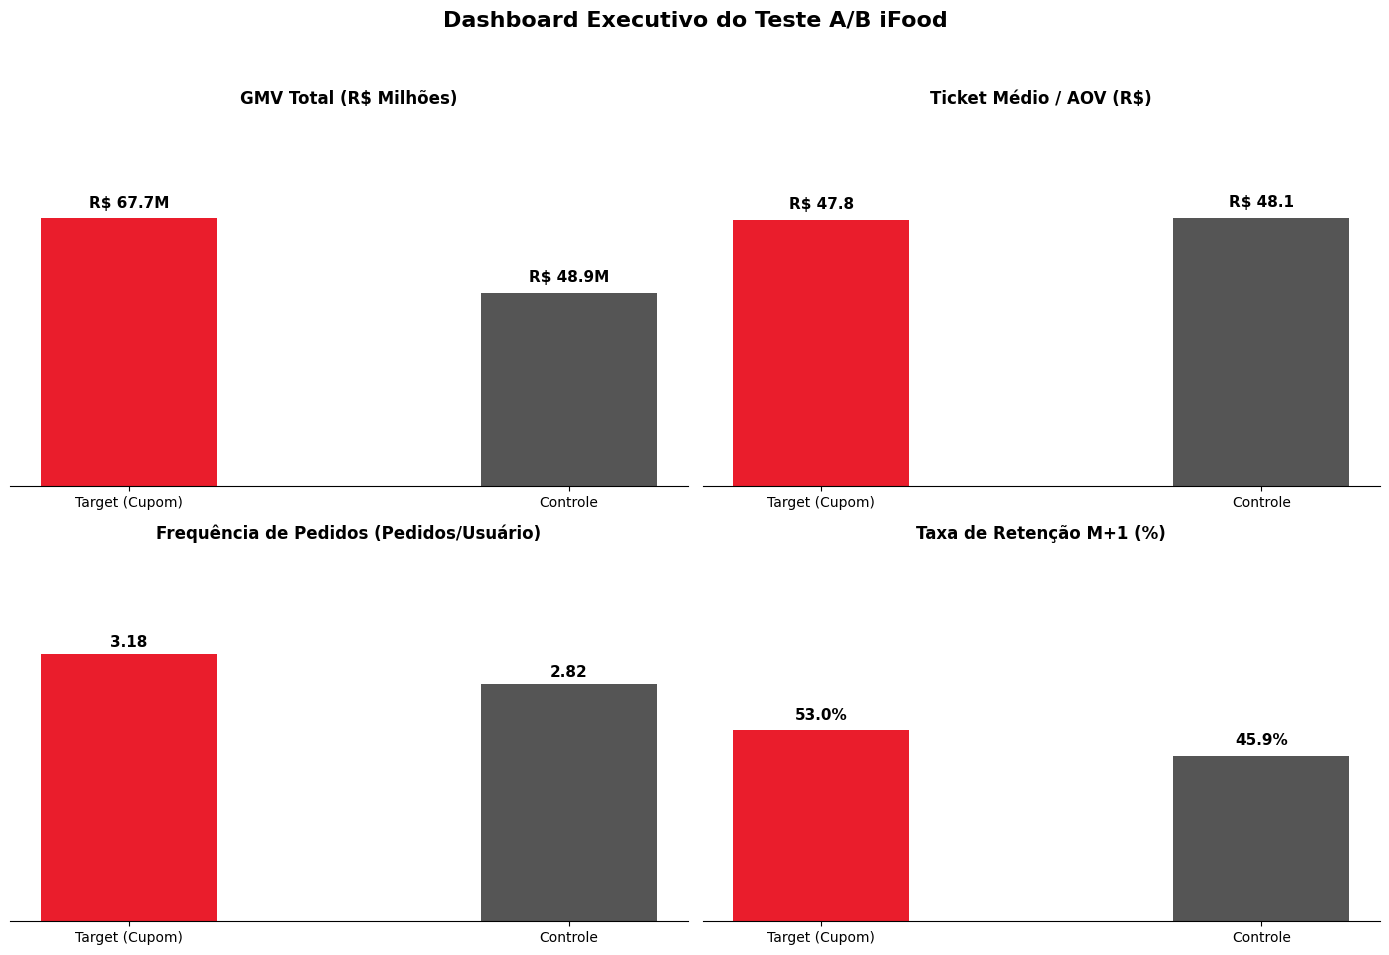

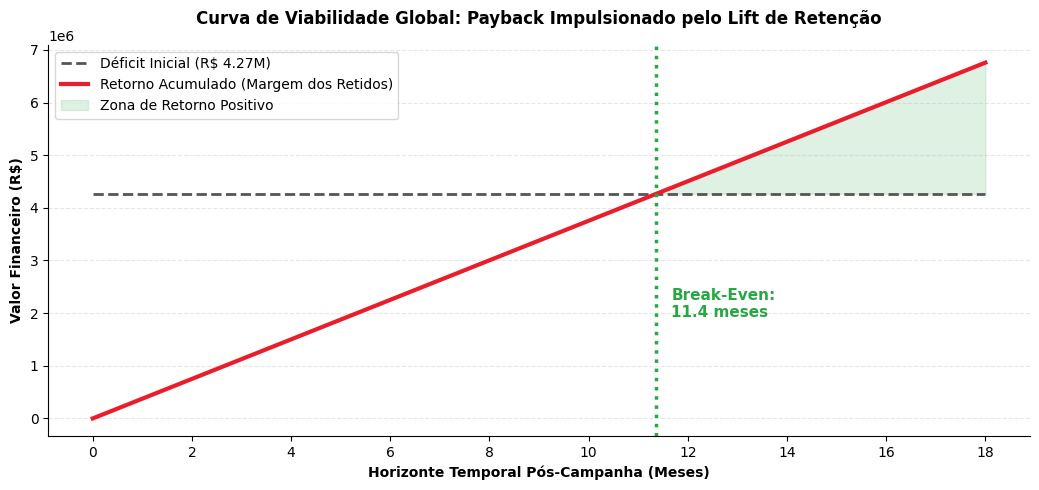

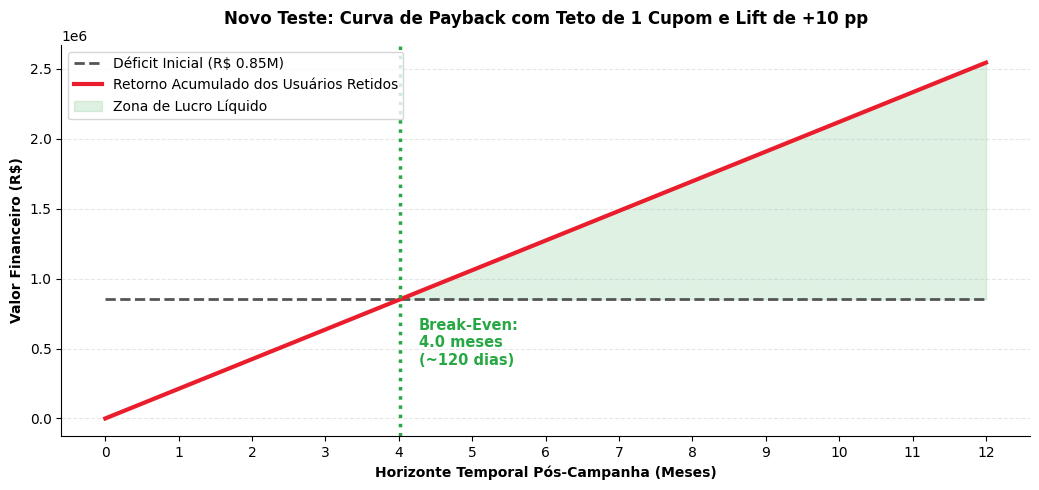

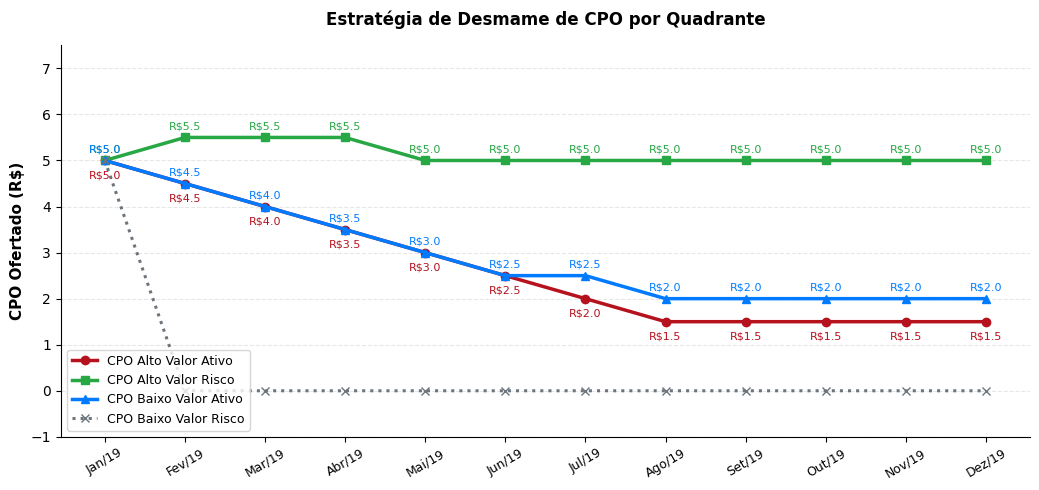

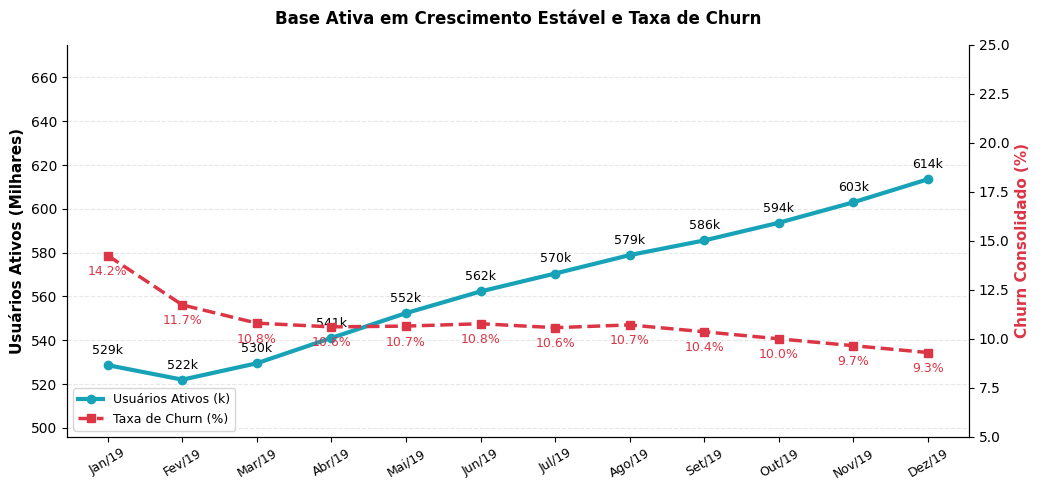

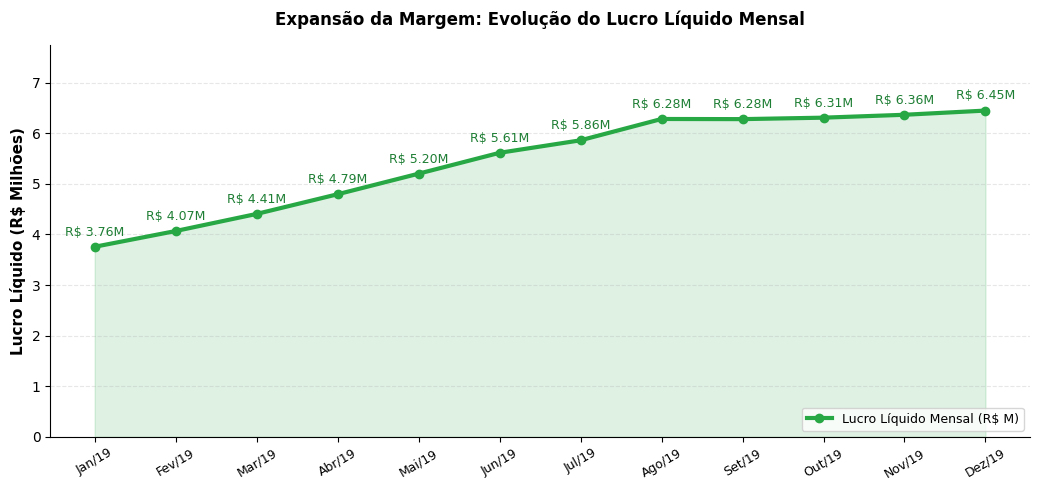

In [0]:
plt.close('all')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Leitura segura dos Data Marts salvos para garantir independência de variáveis
df_resumo_ab = spark.table("gold_dm_ab_test_summary").toPandas().set_index("ab_test_group")
df_simulacao_cpo = spark.table("gold_dm_financial_cpo_projection").toPandas()

# ==============================================================================
# 1. DASHBOARD EXECUTIVO DO TESTE A/B (4 EM 1: GMV, AOV, FREQ, RETENÇÃO)
# ==============================================================================
fig_ab, axes = plt.subplots(2, 2, figsize=(14, 10))
colors_ab = ['#ea1d2c', '#555555']
groups_ab = ['Target (Cupom)', 'Controle']

def clean_axis(ax, title):
    ax.set_title(title, fontsize=12, fontweight='bold', pad=15)
    ax.grid(False)
    for spine in ['top', 'right', 'left']:
        ax.spines[spine].set_visible(False)
    ax.spines['bottom'].set_visible(True)
    ax.set_yticks([])

# 1.1 GMV Total (R$ Milhões)
gmv_tgt_m = float(df_resumo_ab.loc['target', 'total_gmv']) / 1e6
gmv_ctrl_m = float(df_resumo_ab.loc['control', 'total_gmv']) / 1e6
bars1 = axes[0, 0].bar(groups_ab, [gmv_tgt_m, gmv_ctrl_m], color=colors_ab, width=0.4)
clean_axis(axes[0, 0], 'GMV Total (R$ Milhões)')
axes[0, 0].set_ylim(0, max(gmv_tgt_m, gmv_ctrl_m) * 1.35)
for bar in bars1:
    y = bar.get_height()
    axes[0, 0].text(bar.get_x() + bar.get_width()/2.0, y + 2.0, f'R$ {y:.1f}M', ha='center', va='bottom', fontweight='bold', fontsize=11)

# 1.2 Ticket Médio / AOV (R$)
aov_tgt = float(df_resumo_ab.loc['target', 'aov'])
aov_ctrl = float(df_resumo_ab.loc['control', 'aov'])
bars2 = axes[0, 1].bar(groups_ab, [aov_tgt, aov_ctrl], color=colors_ab, width=0.4)
clean_axis(axes[0, 1], 'Ticket Médio / AOV (R$)')
axes[0, 1].set_ylim(0, max(aov_tgt, aov_ctrl) * 1.35)
for bar in bars2:
    y = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2.0, y + 1.5, f'R$ {y:.1f}', ha='center', va='bottom', fontweight='bold', fontsize=11)

# 1.3 Frequência de Pedidos
freq_tgt = float(df_resumo_ab.loc['target', 'frequency'])
freq_ctrl = float(df_resumo_ab.loc['control', 'frequency'])
bars3 = axes[1, 0].bar(groups_ab, [freq_tgt, freq_ctrl], color=colors_ab, width=0.4)
clean_axis(axes[1, 0], 'Frequência de Pedidos (Pedidos/Usuário)')
axes[1, 0].set_ylim(0, max(freq_tgt, freq_ctrl) * 1.35)
for bar in bars3:
    y = bar.get_height()
    axes[1, 0].text(bar.get_x() + bar.get_width()/2.0, y + 0.05, f'{y:.2f}', ha='center', va='bottom', fontweight='bold', fontsize=11)

# 1.4 Taxa de Retenção M+1 (%)
ret_tgt = float(df_resumo_ab.loc['target', 'retention_m1_percentage'])
ret_ctrl = float(df_resumo_ab.loc['control', 'retention_m1_percentage'])
bars4 = axes[1, 1].bar(groups_ab, [ret_tgt, ret_ctrl], color=colors_ab, width=0.4)
clean_axis(axes[1, 1], 'Taxa de Retenção M+1 (%)')
axes[1, 1].set_ylim(0, 100)
for bar in bars4:
    y = bar.get_height()
    axes[1, 1].text(bar.get_x() + bar.get_width()/2.0, y + 2.0, f'{y:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=11)

fig_ab.suptitle('Dashboard Executivo do Teste A/B iFood', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
display(fig_ab)
plt.close(fig_ab)

# ==============================================================================
# 2. CURVA DE PAYBACK: VIABILIDADE GLOBAL DO TESTE A/B (ORIGINAL - 18 MESES)
# ==============================================================================
meses_glob_idx = np.arange(19)
fig_pb_glob, ax_glob = plt.subplots(figsize=(10.5, 5))

deficit_linha_glob = [deficit_campanha] * len(meses_glob_idx)
retorno_linha_glob = [m * receita_incremental_mes for m in meses_glob_idx]

ax_glob.plot(meses_glob_idx, deficit_linha_glob, color='#555555', linestyle='--', linewidth=2, label=f'Déficit Inicial (R$ {deficit_campanha/1e6:.2f}M)')
ax_glob.plot(meses_glob_idx, retorno_linha_glob, color='#ea1d2c', linewidth=3, label='Retorno Acumulado (Margem dos Retidos)')
ax_glob.fill_between(
    meses_glob_idx, retorno_linha_glob, deficit_linha_glob,
    where=(np.array(retorno_linha_glob) >= np.array(deficit_linha_glob)),
    color='#28a745', alpha=0.15, interpolate=True, label='Zona de Retorno Positivo'
)

if 0 < payback_meses <= 18:
    ax_glob.axvline(x=payback_meses, color='#28a745', linestyle=':', linewidth=2.5)
    ax_glob.text(
        payback_meses + 0.3, float(deficit_campanha) * 0.45,
        f'Break-Even:\n{payback_meses:.1f} meses',
        color='#28a745', fontweight='bold', fontsize=11
    )

ax_glob.set_title('Curva de Viabilidade Global: Payback Impulsionado pelo Lift de Retenção', fontsize=12, fontweight='bold', pad=15)
ax_glob.set_xlabel('Horizonte Temporal Pós-Campanha (Meses)', fontsize=10, fontweight='bold')
ax_glob.set_ylabel('Valor Financeiro (R$)', fontsize=10, fontweight='bold')
ax_glob.set_xticks(range(0, 19, 2))
ax_glob.grid(axis='y', linestyle='--', alpha=0.3)
ax_glob.legend(frameon=True, facecolor='white', loc='upper left')
ax_glob.spines['top'].set_visible(False)
ax_glob.spines['right'].set_visible(False)
plt.tight_layout()
display(fig_pb_glob)
plt.close(fig_pb_glob)

# ==============================================================================
# 3. CURVA DE PAYBACK: VIABILIDADE SEGMENTADA (MONOCOMPRADORES - 12 MESES)
# ==============================================================================
meses_mono_idx = np.arange(13)
fig_pb_mono, ax_mono = plt.subplots(figsize=(10.5, 5))

ax_mono.plot(meses_mono_idx, [deficit_liquido_campanha] * len(meses_mono_idx), color='#555555', linestyle='--', linewidth=2, label=f'Déficit Inicial (R$ {deficit_liquido_campanha/1e6:.2f}M)')
ax_mono.plot(meses_mono_idx, [m * margem_recorrente_mensal for m in meses_mono_idx], color='#ea1d2c', linewidth=3, label='Retorno Acumulado dos Usuários Retidos')
ax_mono.fill_between(
    meses_mono_idx, [m * margem_recorrente_mensal for m in meses_mono_idx], [deficit_liquido_campanha] * len(meses_mono_idx),
    where=(np.array([m * margem_recorrente_mensal for m in meses_mono_idx]) >= np.array([deficit_liquido_campanha] * len(meses_mono_idx))),
    color='#28a745', alpha=0.15, interpolate=True, label='Zona de Lucro Líquido'
)

if 0 < payback_deficit_liquido <= 12:
    ax_mono.axvline(x=payback_deficit_liquido, color='#28a745', linestyle=':', linewidth=2.5)
    ax_mono.text(
        payback_deficit_liquido + 0.25, float(deficit_liquido_campanha) * 0.45,
        f'Break-Even:\n{payback_deficit_liquido:.1f} meses\n(~{int(payback_deficit_liquido * 30)} dias)',
        color='#28a745', fontweight='bold', fontsize=10.5
    )

ax_mono.set_title('Novo Teste: Curva de Payback com Teto de 1 Cupom e Lift de +10 pp', fontsize=12, fontweight='bold', pad=15)
ax_mono.set_xlabel('Horizonte Temporal Pós-Campanha (Meses)', fontsize=10, fontweight='bold')
ax_mono.set_ylabel('Valor Financeiro (R$)', fontsize=10, fontweight='bold')
ax_mono.set_xticks(range(0, 13))
ax_mono.grid(axis='y', linestyle='--', alpha=0.3)
ax_mono.legend(frameon=True, facecolor='white', loc='upper left')
ax_mono.spines['top'].set_visible(False)
ax_mono.spines['right'].set_visible(False)
plt.tight_layout()
display(fig_pb_mono)
plt.close(fig_pb_mono)

# ==============================================================================
# 4. OTIMIZAÇÃO DE CPO: ESTRATÉGIA DE DESMAME POR QUADRANTE
# ==============================================================================
x_cpo = np.arange(len(df_simulacao_cpo["mes_referencia"]))
meses_labels = df_simulacao_cpo["mes_referencia"]

fig_cpo, ax1 = plt.subplots(figsize=(10.5, 5))
ax1.plot(x_cpo, df_simulacao_cpo["cpo_alto_ativo"], marker='o', linewidth=2.5, color='#b5121e', label='CPO Alto Valor Ativo')
ax1.plot(x_cpo, df_simulacao_cpo["cpo_alto_risco"], marker='s', linewidth=2.5, color='#28a745', label='CPO Alto Valor Risco')
ax1.plot(x_cpo, df_simulacao_cpo["cpo_baixo_ativo"], marker='^', linewidth=2.5, color='#007bff', label='CPO Baixo Valor Ativo')
ax1.plot(x_cpo, df_simulacao_cpo["cpo_baixo_risco"], marker='x', linewidth=2.2, color='#6c757d', linestyle=':', label='CPO Baixo Valor Risco')

for i in range(len(x_cpo)):
    ax1.annotate(f"R${df_simulacao_cpo['cpo_alto_ativo'][i]:.1f}", (x_cpo[i], df_simulacao_cpo['cpo_alto_ativo'][i]), textcoords="offset points", xytext=(0, -13), ha='center', fontsize=8, color='#b5121e')
    ax1.annotate(f"R${df_simulacao_cpo['cpo_alto_risco'][i]:.1f}", (x_cpo[i], df_simulacao_cpo['cpo_alto_risco'][i]), textcoords="offset points", xytext=(0, 6), ha='center', fontsize=8, color='#28a745')
    ax1.annotate(f"R${df_simulacao_cpo['cpo_baixo_ativo'][i]:.1f}", (x_cpo[i], df_simulacao_cpo['cpo_baixo_ativo'][i]), textcoords="offset points", xytext=(0, 6), ha='center', fontsize=8, color='#007bff')

ax1.set_title("Estratégia de Desmame de CPO por Quadrante", fontsize=12, pad=15, fontweight='bold')
ax1.set_xticks(x_cpo)
ax1.set_xticklabels(meses_labels, fontsize=9, rotation=30)
ax1.set_ylabel("CPO Ofertado (R$)", fontsize=11, fontweight='bold')
ax1.set_ylim(-1.0, 7.5)
ax1.grid(axis='y', linestyle='--', alpha=0.3)
ax1.legend(loc='lower left', frameon=True, facecolor='white', fontsize=9)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
plt.tight_layout()
display(fig_cpo)
plt.close(fig_cpo)

# ==============================================================================
# 5. OTIMIZAÇÃO DE CPO: BASE ATIVA TOTAL E TAXA DE CHURN CONTROLADA
# ==============================================================================
fig_base, ax2 = plt.subplots(figsize=(10.5, 5))
ax2.plot(x_cpo, df_simulacao_cpo["total_ativos"] / 1e3, marker='o', linewidth=3, color='#17a2b8', label='Usuários Ativos (k)')
for i, txt in enumerate(df_simulacao_cpo["total_ativos"]):
    ax2.annotate(f"{txt/1e3:.0f}k", (x_cpo[i], txt/1e3), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=9)

ax2.set_title("Base Ativa em Crescimento Estável e Taxa de Churn", fontsize=12, pad=15, fontweight='bold')
ax2.set_xticks(x_cpo)
ax2.set_xticklabels(meses_labels, fontsize=9, rotation=30)
ax2.set_ylabel("Usuários Ativos (Milhares)", fontsize=11, fontweight='bold')
ax2.set_ylim(min(df_simulacao_cpo["total_ativos"] / 1e3) * 0.95, max(df_simulacao_cpo["total_ativos"] / 1e3) * 1.10)
ax2.grid(axis='y', linestyle='--', alpha=0.3)

ax2_twin = ax2.twinx()
ax2_twin.plot(x_cpo, df_simulacao_cpo["taxa_churn_total_pct"], color='#dc3545', linestyle='--', linewidth=2.5, marker='s', label='Taxa de Churn (%)')
for i, churn in enumerate(df_simulacao_cpo["taxa_churn_total_pct"]):
    ax2_twin.annotate(f"{churn:.1f}%", (x_cpo[i], churn), textcoords="offset points", xytext=(0, -14), ha='center', fontsize=9, color='#dc3545')

ax2_twin.set_ylabel("Churn Consolidado (%)", fontsize=11, color='#dc3545', fontweight='bold')
ax2_twin.set_ylim(5.0, 25.0)
ax2_twin.spines['top'].set_visible(False)

lines_1, labels_1 = ax2.get_legend_handles_labels()
lines_2, labels_2 = ax2_twin.get_legend_handles_labels()
ax2.legend(lines_1 + lines_2, labels_1 + labels_2, loc='lower left', frameon=True, facecolor='white', fontsize=9)
ax2.spines['top'].set_visible(False)
plt.tight_layout()
display(fig_base)
plt.close(fig_base)

# ==============================================================================
# 6. OTIMIZAÇÃO DE CPO: EVOLUÇÃO DO LUCRO LÍQUIDO MENSAL
# ==============================================================================
fig_lucro, ax3 = plt.subplots(figsize=(10.5, 5))
lucro_milhoes = df_simulacao_cpo["lucro_total_liquido"] / 1e6

ax3.plot(x_cpo, lucro_milhoes, marker='o', linewidth=3, color='#28a745', label='Lucro Líquido Mensal (R$ M)')
ax3.fill_between(x_cpo, lucro_milhoes, 0, alpha=0.15, color='#28a745')

for i, val in enumerate(lucro_milhoes):
    ax3.annotate(f"R$ {val:.2f}M", (x_cpo[i], val), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=9, color='#1e7e34')

ax3.set_title("Expansão da Margem: Evolução do Lucro Líquido Mensal", fontsize=12, pad=15, fontweight='bold')
ax3.set_xticks(x_cpo)
ax3.set_xticklabels(meses_labels, fontsize=9, rotation=30)
ax3.set_ylabel("Lucro Líquido (R$ Milhões)", fontsize=11, fontweight='bold')
ax3.set_ylim(0, max(lucro_milhoes) * 1.20)
ax3.grid(axis='y', linestyle='--', alpha=0.3)
ax3.legend(loc='lower right', frameon=True, facecolor='white', fontsize=9)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
plt.tight_layout()
display(fig_lucro)
plt.close(fig_lucro)

In [0]:
import time
end_time_notebook = time.time()
total_duration_seconds = end_time_notebook - start_time_notebook
total_duration_minutes = total_duration_seconds / 60
analytics_duration_seconds = total_duration_seconds - etl_duration_seconds
analytics_duration_minutes = total_duration_minutes - etl_duration_minutes

print("="*60)
print("🚀 EXECUÇÃO DO NOTEBOOK CONCLUÍDA")
print("="*60)
print(f"⏱️ Tempo ETL: {etl_duration_minutes:.2f} min")
print(f"⏱️ Tempo Data Marts e Análise: {analytics_duration_minutes:.2f} min")
print("-" * 60)
print(f"🕒 TEMPO TOTAL DE EXECUÇÃO: {total_duration_seconds:.2f} segundos ({total_duration_minutes:.2f} minutos)")
print("="*60)

🚀 EXECUÇÃO DO NOTEBOOK CONCLUÍDA
⏱️ Tempo ETL: 6.47 min
⏱️ Tempo Data Marts e Análise: 1.03 min
------------------------------------------------------------
🕒 TEMPO TOTAL DE EXECUÇÃO: 450.07 segundos (7.50 minutos)
